# Lab 6 · CNN + LSTM for action and gesture recognition

**Course lab:** `CV-Week3-Lecture6.ipynb` (in `course-files/labs/`)
**Theory partner:** [notes/06_video_rnn_lstm.md](../notes/06_video_rnn_lstm.md) and [notebooks/06_video_sequence_models_rnn_lstm.ipynb](../notebooks/06_video_sequence_models_rnn_lstm.ipynb)

| Course cell | What it does | What you will see here |
|---|---|---|
| Setup: `VideoDataset` loader | reads frames from video files with OpenCV | the loader reading **real `.mp4` files** from disk, plus three bugs that stop it from working |
| Exercise: CNN + LSTM | a small CNN per frame, an LSTM over time | the course's model trained on labelled videos, with a training curve and **held-out** accuracy |
| Mini project: gesture recognition | predict a gesture class | a confusion matrix, per-video predictions, and a comparison with two **order-blind** baselines that shows *why* the LSTM is needed |

**What you will learn:** how a video becomes a `[batch, time, channels, height, width]` tensor, what `batch_first=True` means, where the `32*16*16` comes from, and how to prove that a model is really using the order of frames.

**Run time:** about 15–20 minutes on the shared CPU this was built on (the CNN + LSTM alone trained for 887 s); expect less on an idle laptop. On a Colab GPU: under a minute.

## 0 · Theory in 60 seconds (details in notes chapter 06)

- A **video** is a sequence of frames. Recognising an **action** needs *what* is in each frame (**spatial** features: a hand, its shape) and *how it changes over time* (**temporal** features: the hand moves left).
- **CNN + LSTM pipeline:** run the same CNN on every frame to get one feature vector per frame, feed the sequence of vectors into an **LSTM**, and classify from the LSTM's final hidden state.
- **LSTM** (*Long Short-Term Memory*): an RNN with a **cell state** and three **gates** (forget, input, output) that decide what to drop, what to add and what to output at each step, so information can survive many time steps without the vanishing-gradient problem of a plain RNN.

### The dataset: why synthetic, and what it contains

The course leaves the video folder as a placeholder (`./videos/train`) and every label as `0`. Real action datasets (UCF101: 6.5 GB, HMDB51, Jester gestures: 22 GB) are far too big for a quick lab, so we **generate a small synthetic gesture dataset** and **write it as real `.mp4` files**, so the course's OpenCV reading code is exercised for real.

> ⚠️ **Synthetic data.** Each clip shows a skin-coloured "hand" blob on a noisy background with a static distractor object, performing one of **5 gestures**: `swipe_left`, `swipe_right`, `swipe_up`, `swipe_down`, `circle`. Start position, size, speed, clip length (10–24 frames) and colours are random. Every swipe passes through a random centre point, so **`swipe_left` and `swipe_right` contain exactly the same kind of frames, only in opposite order** (likewise up/down). That is deliberate: a model can only tell them apart by using **time order**, which is exactly what the LSTM is for.

In [1]:
%matplotlib inline
import os, time, random, shutil
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(2)                     # share the CPU politely; raise on your own machine
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| OpenCV", cv2.__version__, "| device:", device)

CLASSES = ["swipe_left", "swipe_right", "swipe_up", "swipe_down", "circle"]
VID_ROOT = os.path.join("data", "videos")
SIZE = 64

def make_clip(cls, rng):
    """Return a list of HxWx3 uint8 BGR frames showing one gesture."""
    n = int(rng.integers(10, 25))                                   # clip length varies: 10..24 frames
    bg = np.full((SIZE, SIZE, 3), rng.integers(20, 90, 3), np.float32)
    bg += cv2.GaussianBlur(rng.normal(0, 25, (SIZE, SIZE, 3)).astype(np.float32), (0, 0), 3)   # blotchy background
    dx, dy = int(rng.integers(6, 58)), int(rng.integers(6, 58))     # a static distractor square
    cv2.rectangle(bg, (dx - 4, dy - 4), (dx + 4, dy + 4), tuple(float(v) for v in rng.integers(100, 255, 3)), -1)
    cx, cy = rng.uniform(22, 42, 2)                                  # centre of the gesture
    amp = rng.uniform(12, 20); r = int(rng.integers(5, 9))
    skin = np.array([rng.uniform(60, 120), rng.uniform(110, 170), rng.uniform(170, 240)])   # BGR skin-ish tone
    t = np.linspace(-1, 1, n)
    if cls == "swipe_left":  xs, ys = cx - amp * t, cy + 0 * t
    if cls == "swipe_right": xs, ys = cx + amp * t, cy + 0 * t
    if cls == "swipe_up":    xs, ys = cx + 0 * t, cy - amp * t
    if cls == "swipe_down":  xs, ys = cx + 0 * t, cy + amp * t
    if cls == "circle":
        a0 = rng.uniform(0, 2 * np.pi)
        xs, ys = cx + 0.8 * amp * np.cos(a0 + np.pi * (t + 1)), cy + 0.8 * amp * np.sin(a0 + np.pi * (t + 1))
    frames = []
    for x, y in zip(xs, ys):
        f = bg.copy()
        cv2.ellipse(f, (int(x), int(y)), (r, int(r * 1.3)), 0, 0, 360, tuple(float(v) for v in skin), -1)
        f += rng.normal(0, 8, f.shape)                               # sensor noise
        frames.append(np.clip(f, 0, 255).astype(np.uint8))
    return frames

def write_video(path, frames, fps=10):
    w = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (SIZE, SIZE))
    for f in frames:
        w.write(f)
    w.release()

N_PER_CLASS = {"train": 60, "test": 20}
rng = np.random.default_rng(0)
if os.path.isdir(VID_ROOT):
    shutil.rmtree(VID_ROOT)                                          # regenerate from scratch every run
for split, n in N_PER_CLASS.items():
    for cls in CLASSES:
        os.makedirs(os.path.join(VID_ROOT, split, cls), exist_ok=True)
        for i in range(n):
            write_video(os.path.join(VID_ROOT, split, cls, f"{cls}_{i:03d}.mp4"), make_clip(cls, rng))
for split in N_PER_CLASS:
    print(split, {c: len(os.listdir(os.path.join(VID_ROOT, split, c))) for c in CLASSES})

torch 2.14.1+cu130 | OpenCV 5.0.0 | device: cpu


train {'swipe_left': 60, 'swipe_right': 60, 'swipe_up': 60, 'swipe_down': 60, 'circle': 60}
test {'swipe_left': 20, 'swipe_right': 20, 'swipe_up': 20, 'swipe_down': 20, 'circle': 20}


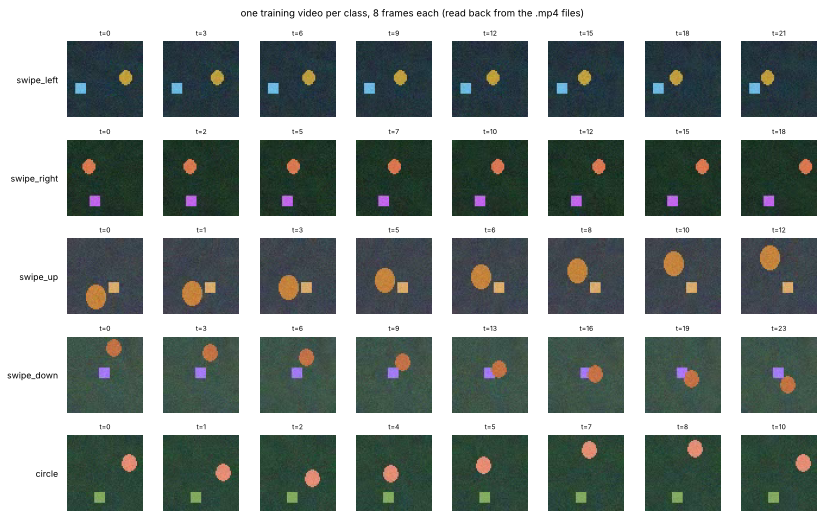

In [2]:
def read_all_frames(path):
    cap = cv2.VideoCapture(path); frames = []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
    cap.release()
    return frames

fig, ax = plt.subplots(len(CLASSES), 8, figsize=(12, 7.5), dpi=70)
for row, cls in enumerate(CLASSES):
    fr = read_all_frames(os.path.join(VID_ROOT, "train", cls, f"{cls}_000.mp4"))
    for j, k in enumerate(np.linspace(0, len(fr) - 1, 8).astype(int)):
        ax[row, j].imshow(fr[k]); ax[row, j].axis("off")
        ax[row, j].set_title(f"t={k}", fontsize=7)
    ax[row, 0].text(-8, 32, cls, fontsize=9, ha="right", va="center")
plt.suptitle("one training video per class, 8 frames each (read back from the .mp4 files)", fontsize=10)
plt.tight_layout(); plt.show()

## 1 · Setup: the course's `VideoDataset`

```python
self.videos = os.listdir(video_dir)                     # every entry in the folder is assumed to be a video file
cap = cv2.VideoCapture(video_path)                      # open the video
while len(frames) < self.seq_len and cap.isOpened():   # read up to seq_len (16) frames from the START
    ret, frame = cap.read()                             # ret = False when the video has ended
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)      # OpenCV gives BGR, PyTorch/matplotlib expect RGB
    frame = self.transform(frame)                       # ToTensor -> [3,H,W] in 0..1, then Resize((64,64))
frames = torch.stack(frames)                            # -> [T, 3, 64, 64]
label = 0                                               # placeholder, replace with actual label
```

Three problems, which we demonstrate one at a time:
1. **Folder layout.** Pointed at a folder that contains class *sub-folders*, `os.listdir` returns folder names; OpenCV cannot open a folder, zero frames are read and `torch.stack([])` fails.
2. **`label = 0` for every video.** Even pointed at a flat folder of videos it loads, but **every label is 0**. Training would quickly learn "always answer 0": loss → 0, knowledge → 0.
3. **Clips shorter than `seq_len`.** A 12-frame clip gives a `[12,3,64,64]` tensor, a 20-frame clip gives `[16,3,64,64]`. The `DataLoader` cannot stack different lengths into a batch.

In [3]:
# The course's dataset class, unchanged
class VideoDataset(Dataset):
    def __init__(self, video_dir, transform=None, seq_len=16):
        self.video_dir = video_dir
        self.videos = os.listdir(video_dir)
        self.transform = transform
        self.seq_len = seq_len
    def __len__(self):
        return len(self.videos)
    def __getitem__(self, idx):
        video_path = os.path.join(self.video_dir, self.videos[idx])
        cap = cv2.VideoCapture(video_path)
        frames = []
        while len(frames) < self.seq_len and cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            if self.transform:
                frame = self.transform(frame)
            frames.append(frame)
        cap.release()
        frames = torch.stack(frames)
        label = 0  # placeholder, replace with actual label
        return frames, label

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((64,64))
])

# Problem 1: the class-folder layout
train_dataset = VideoDataset(os.path.join(VID_ROOT, "train"), transform=transform)
print("Loaded video dataset with", len(train_dataset), "videos   <- these are the 5 class folders:", train_dataset.videos)
try:
    train_dataset[0]
except Exception as e:
    print("  reading item 0 ->", type(e).__name__ + ":", str(e)[:80])

# Problems 2 and 3: a flat folder of mixed-length videos
flat = VideoDataset(os.path.join(VID_ROOT, "train", "swipe_right"), transform=transform)
lengths = [flat[i][0].shape[0] for i in range(10)]
print("\nflat folder:", len(flat), "videos | labels of the first 10:", [flat[i][1] for i in range(10)])
print("frames returned for the first 10 videos:", lengths)
try:
    for frames, labels in DataLoader(flat, batch_size=2, shuffle=False):
        pass
    print("all batches stacked fine")
except Exception as e:
    print("DataLoader ->", type(e).__name__ + ":", str(e)[:110])

Loaded video dataset with 5 videos   <- these are the 5 class folders: ['swipe_right', 'swipe_left', 'swipe_down', 'swipe_up', 'circle']
  reading item 0 -> RuntimeError: stack expects a non-empty TensorList



flat folder: 60 videos | labels of the first 10: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
frames returned for the first 10 videos: [16, 16, 16, 10, 16, 16, 16, 16, 14, 11]
DataLoader -> RuntimeError: stack expects each tensor to be equal size, but got [16, 3, 64, 64] at entry 0 and [10, 3, 64, 64] at entry 1


### The fixed `VideoDataset`

- **Labels from folder names:** `videos/train/<class_name>/*.mp4`, label = index of the class name. This is the same convention as `torchvision.datasets.ImageFolder`.
- **Every clip → exactly `seq_len` frames by uniform temporal sampling:** read all frames, pick `seq_len` indices spread evenly from the first to the last frame (`np.linspace`). Short clips repeat some frames, long clips skip some. Unlike "the first 16 frames", this always covers the **whole gesture**, and every sample has the same shape so batching works.
- **A held-out test split** in `videos/test/`, never used for training.
- **A RAM cache**: decoding the same 300 videos again in every epoch is wasted work, so each clip is decoded once and kept in memory (400 clips × 16 × 3 × 64 × 64 floats ≈ 315 MB). Turn it off (`cache=False`) for a large dataset that doesn't fit in RAM. (No random augmentation here, so caching changes nothing about the training.)
- `transform` stays the course's `ToTensor()` + `Resize((64,64))` (our frames are already 64×64, so the resize does nothing here, but it would for real camera video).

In [4]:
class VideoDataset(Dataset):
    """Fixed: labels from class folders, fixed-length uniform temporal sampling, optional RAM cache."""
    def __init__(self, video_dir, transform=None, seq_len=16, cache=True):
        self.classes = sorted(d for d in os.listdir(video_dir) if os.path.isdir(os.path.join(video_dir, d)))
        self.samples = [(os.path.join(video_dir, c, f), i)                       # (path, label)
                        for i, c in enumerate(self.classes) for f in sorted(os.listdir(os.path.join(video_dir, c)))]
        self.transform = transform
        self.seq_len = seq_len
        self.cache = {} if cache else None                                       # decoded clips kept in RAM
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        if self.cache is not None and idx in self.cache:
            return self.cache[idx]
        video_path, label = self.samples[idx]
        cap = cv2.VideoCapture(video_path)
        frames = []
        while cap.isOpened():                                                    # read the WHOLE clip
            ret, frame = cap.read()
            if not ret:
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        cap.release()
        if len(frames) == 0:
            raise IOError(f"could not read any frame from {video_path}")
        idxs = np.linspace(0, len(frames) - 1, self.seq_len).round().astype(int)   # uniform sampling
        frames = [self.transform(frames[i]) if self.transform else torch.from_numpy(frames[i]) for i in idxs]
        item = (torch.stack(frames), label)
        if self.cache is not None:
            self.cache[idx] = item
        return item

train_dataset = VideoDataset(os.path.join(VID_ROOT, "train"), transform=transform)
test_dataset = VideoDataset(os.path.join(VID_ROOT, "test"), transform=transform)
assert train_dataset.classes == sorted(CLASSES)
CLASS_NAMES = train_dataset.classes
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=20, shuffle=False)

frames, labels = next(iter(train_loader))
print("Loaded video dataset with", len(train_dataset), "training and", len(test_dataset), "test videos")
print("classes:", CLASS_NAMES)
print("one batch: frames", tuple(frames.shape), "= [batch, time, channels, height, width] | labels", labels.tolist())

Loaded video dataset with 300 training and 100 test videos
classes: ['circle', 'swipe_down', 'swipe_left', 'swipe_right', 'swipe_up']
one batch: frames (8, 16, 3, 64, 64) = [batch, time, channels, height, width] | labels [0, 1, 1, 3, 2, 0, 0, 0]


## 2 · Exercise: action recognition with CNN + LSTM

The course's model, line by line:

```python
self.cnn = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 3x64x64  -> 16x32x32
                         nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))    # 16x32x32 -> 32x16x16
self.lstm = nn.LSTM(32*16*16, hidden_dim, batch_first=True)
self.fc = nn.Linear(hidden_dim, num_classes)
```

- **Why `32*16*16`?** Each frame is 64×64; two `MaxPool2d(2)` halve it twice → 16×16, and the last conv has 32 channels. Flattened, each frame becomes a vector of **32 × 16 × 16 = 8,192** numbers. That is the LSTM's `input_size`. Change the frame size (say to 128×128) and this must become `32*32*32`, otherwise you get a shape error.
- **`batch_first=True`**: the LSTM expects input shaped **`[batch, time, features]`** (here `[8, 16, 8192]`). Without it PyTorch expects `[time, batch, features]`, and the batch and time axes would be silently swapped.
- **`forward`**: a loop over the 16 time steps runs the *same* CNN on each frame (`x[:, t]` = frame t of every video in the batch, `[B,3,64,64]`), flattens it (`.view(batch_size, -1)`), and `torch.stack(..., dim=1)` rebuilds `[B, T, 8192]`.
- **`lstm_out[:, -1, :]`**: the LSTM returns a hidden state for **every** time step (`[B, T, 128]`); we keep the **last** one, which has "seen" the whole clip, and the `Linear` layer maps it to 5 class scores (logits).
- **`CrossEntropyLoss`** takes these logits and the integer labels (it applies softmax internally).

In [5]:
# The course's model, unchanged
class CNN_LSTM(nn.Module):
    def __init__(self, hidden_dim=128, num_classes=5):
        super(CNN_LSTM, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.lstm = nn.LSTM(32*16*16, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)
    def forward(self, x):
        batch_size, seq_len, c, h, w = x.size()
        cnn_out = []
        for t in range(seq_len):
            out = self.cnn(x[:,t])
            out = out.view(batch_size, -1)
            cnn_out.append(out)
        cnn_out = torch.stack(cnn_out, dim=1)
        lstm_out, _ = self.lstm(cnn_out)
        out = self.fc(lstm_out[:,-1,:])
        return out

m = CNN_LSTM()
x = torch.zeros(2, 16, 3, 64, 64)
feats = torch.stack([m.cnn(x[:, t]).view(2, -1) for t in range(16)], dim=1)
print("input", tuple(x.shape), "-> CNN per frame", tuple(m.cnn(x[:, 0]).shape), "-> flattened sequence", tuple(feats.shape),
      "-> LSTM out", tuple(m.lstm(feats)[0].shape), "-> logits", tuple(m(x).shape))
print(f"parameters: CNN {sum(p.numel() for p in m.cnn.parameters()):,} | LSTM {sum(p.numel() for p in m.lstm.parameters()):,} | FC {sum(p.numel() for p in m.fc.parameters()):,}")

input (2, 16, 3, 64, 64) -> CNN per frame (2, 32, 16, 16) -> flattened sequence (2, 16, 8192) -> LSTM out (2, 16, 128) -> logits (2, 5)
parameters: CNN 5,088 | LSTM 4,260,864 | FC 645


### Two order-blind baselines

To check that the LSTM really uses *motion*, we train two models with the **same CNN** but no sequence model:
- **`FrameAverage`**: CNN features of all 16 frames are **averaged** over time, then a `Linear` layer classifies. It sees every frame but **not their order** (shuffle the frames and the output is identical).
- **`SingleFrame`**: classifies from the **middle frame only**, like an image classifier.

If the LSTM is doing its job it should beat both, and the baselines should confuse exactly the pairs that differ only in direction (left/right, up/down).

In [6]:
class FrameAverage(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.cnn = CNN_LSTM().cnn                                  # same CNN architecture
        self.fc = nn.Linear(32*16*16, num_classes)
    def forward(self, x):
        b, t = x.shape[:2]
        f = self.cnn(x.flatten(0, 1)).view(b, t, -1)               # all frames in one go: [B*T,3,64,64] -> [B,T,8192]
        return self.fc(f.mean(dim=1))                              # average over time: order is lost

class SingleFrame(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.cnn = CNN_LSTM().cnn
        self.fc = nn.Linear(32*16*16, num_classes)
    def forward(self, x):
        return self.fc(self.cnn(x[:, x.shape[1] // 2]).flatten(1))  # the middle frame only

@torch.no_grad()
def evaluate(model, loader):
    model.eval()                                                  # FIX: evaluation mode
    preds, ys = [], []
    for frames, labels in loader:
        preds.append(model(frames.to(device)).argmax(1).cpu()); ys.append(labels)
    preds, ys = torch.cat(preds), torch.cat(ys)
    return (preds == ys).float().mean().item(), preds, ys

def train(model, epochs=15, lr=0.001):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"loss": [], "train_acc": [], "test_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, seen = 0.0, 0, 0
        for frames, labels in train_loader:
            frames, labels = frames.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(frames)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item(); seen += len(labels)
        hist["loss"].append(running_loss / len(train_loader)); hist["train_acc"].append(correct / seen)
        hist["test_acc"].append(evaluate(model, test_loader)[0])
        print(f"  Epoch {epoch:2d}, Loss: {hist['loss'][-1]:.4f}, train acc {hist['train_acc'][-1]:.2f}, test acc {hist['test_acc'][-1]:.2f}")
    return hist

EPOCHS = 12
models, hists, times = {}, {}, {}
for name, make in [("CNN_LSTM", CNN_LSTM), ("FrameAverage", FrameAverage), ("SingleFrame", SingleFrame)]:
    torch.manual_seed(0)
    print(name)
    t = time.time()
    models[name] = make()
    hists[name] = train(models[name], EPOCHS)
    times[name] = time.time() - t

CNN_LSTM


  Epoch  1, Loss: 1.3502, train acc 0.49, test acc 0.64


  Epoch  2, Loss: 0.7465, train acc 0.69, test acc 0.67


  Epoch  3, Loss: 0.5424, train acc 0.77, test acc 0.75


  Epoch  4, Loss: 0.3481, train acc 0.87, test acc 0.85


...

  Epoch  8, Loss: 0.9525, train acc 0.62, test acc 0.24


  Epoch  9, Loss: 0.7988, train acc 0.74, test acc 0.25


  Epoch 10, Loss: 0.7733, train acc 0.72, test acc 0.20


  Epoch 11, Loss: 0.6038, train acc 0.78, test acc 0.18


  Epoch 12, Loss: 0.4941, train acc 0.82, test acc 0.25


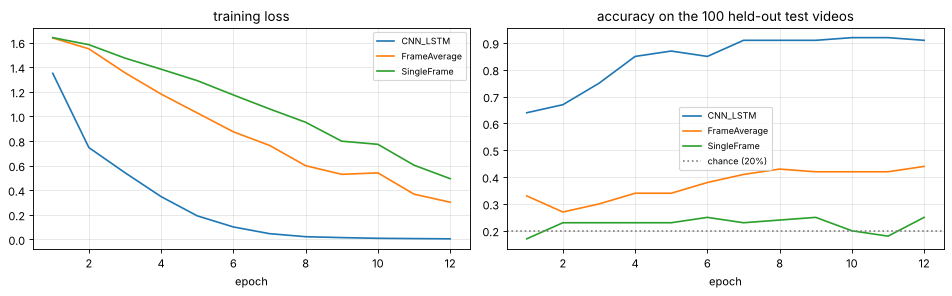

model             params train time  test accuracy


CNN_LSTM       4,266,597       887s          91.0%


FrameAverage      46,053       111s          44.0%
SingleFrame       46,053         4s          25.0%


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), dpi=80)
for name, h in hists.items():
    ax[0].plot(range(1, EPOCHS + 1), h["loss"], label=name)
    ax[1].plot(range(1, EPOCHS + 1), h["test_acc"], label=name)
ax[1].axhline(1 / len(CLASSES), color="grey", ls=":", label="chance (20%)")
ax[0].set_title("training loss"); ax[1].set_title("accuracy on the 100 held-out test videos")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'model':13s} {'params':>10s} {'train time':>10s} {'test accuracy':>14s}")
for name, m in models.items():
    acc = evaluate(m, test_loader)[0]
    print(f"{name:13s} {sum(p.numel() for p in m.parameters()):>10,} {times[name]:>9.0f}s {acc:>14.1%}")

## 3 · Mini project: gesture recognition

The course's mini-project cell takes a batch **from the training loader**, predicts, and prints the class of the first video. We evaluate on the **test** videos instead and look at *which* gestures get confused.

CNN_LSTM     : left<->right confusions  0/40, up<->down confusions  1/40


FrameAverage : left<->right confusions 17/40, up<->down confusions 15/40
SingleFrame  : left<->right confusions 12/40, up<->down confusions  3/40


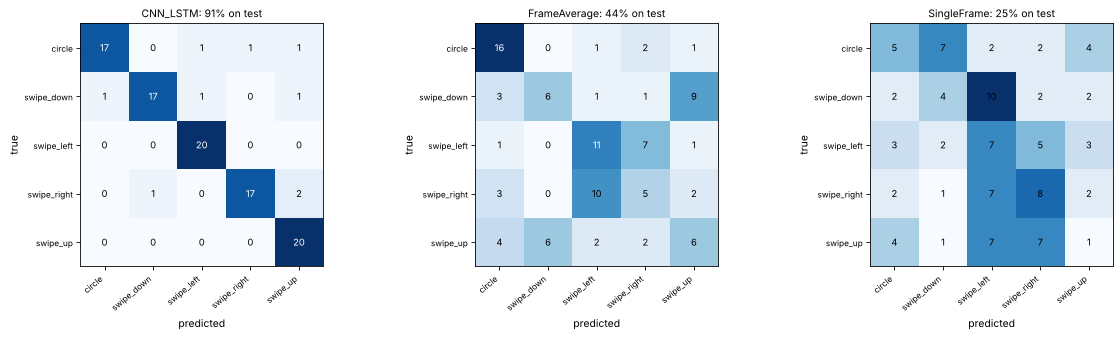

In [8]:
from sklearn.metrics import confusion_matrix

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), dpi=75)
for a, name in zip(ax, models):
    acc, preds, ys = evaluate(models[name], test_loader)
    cm = confusion_matrix(ys, preds, labels=range(len(CLASS_NAMES)))
    a.imshow(cm, cmap="Blues")
    for i in range(len(CLASS_NAMES)):
        for j in range(len(CLASS_NAMES)):
            a.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 10 else "black", fontsize=9)
    a.set_xticks(range(5)); a.set_xticklabels(CLASS_NAMES, rotation=40, ha="right", fontsize=8)
    a.set_yticks(range(5)); a.set_yticklabels(CLASS_NAMES, fontsize=8)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{name}: {acc:.0%} on test", fontsize=10)
    pair = lambda i, j: cm[i, j] + cm[j, i]
    L, Rr, U, D = (CLASS_NAMES.index(c) for c in ("swipe_left", "swipe_right", "swipe_up", "swipe_down"))
    print(f"{name:13s}: left<->right confusions {pair(L, Rr):2d}/40, up<->down confusions {pair(U, D):2d}/40")
plt.tight_layout(); plt.show()

video 0: Predicted gesture class: 1 = swipe_down  (true: swipe_down, confidence 98%)
video 1: Predicted gesture class: 0 = circle      (true: circle, confidence 99%)
video 2: Predicted gesture class: 2 = swipe_left  (true: swipe_left, confidence 94%)
video 3: Predicted gesture class: 2 = swipe_left  (true: swipe_left, confidence 67%)
video 4: Predicted gesture class: 0 = circle      (true: circle, confidence 100%)
video 5: Predicted gesture class: 3 = swipe_right (true: swipe_right, confidence 100%)


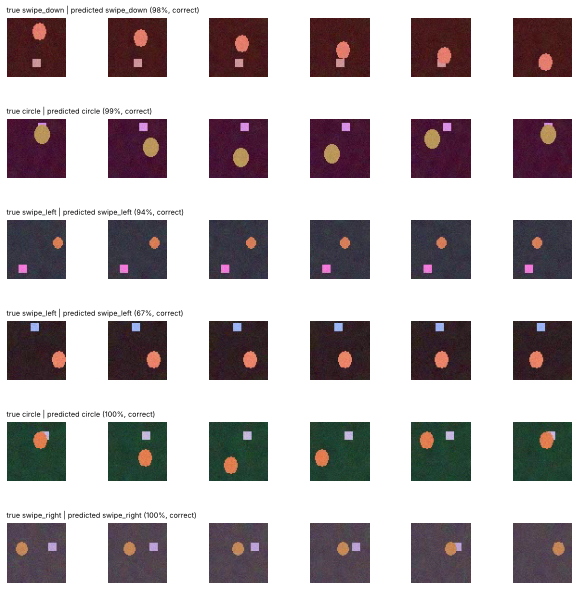

In [9]:
# The course's mini-project cell, done on TEST videos, with class names and confidence
model = models["CNN_LSTM"].eval()
frames, labels = next(iter(DataLoader(test_dataset, batch_size=6, shuffle=True, generator=torch.Generator().manual_seed(3))))
with torch.no_grad():
    probs = torch.softmax(model(frames.to(device)), dim=1).cpu()
_, predicted = torch.max(probs, 1)

fig, ax = plt.subplots(6, 6, figsize=(9, 9.5), dpi=65)
for i in range(6):
    for j, t in enumerate([0, 3, 6, 9, 12, 15]):
        ax[i, j].imshow(frames[i][t].permute(1, 2, 0)); ax[i, j].axis("off")
    ok = "correct" if predicted[i] == labels[i] else "WRONG"
    ax[i, 0].set_title(f"true {CLASS_NAMES[labels[i]]} | predicted {CLASS_NAMES[predicted[i]]} ({probs[i, predicted[i]]:.0%}, {ok})",
                       fontsize=8, loc="left")
    print(f"video {i}: Predicted gesture class: {predicted[i].item()} = {CLASS_NAMES[predicted[i]]:11s} "
          f"(true: {CLASS_NAMES[labels[i]]}, confidence {probs[i, predicted[i]]:.0%})")
plt.tight_layout(); plt.show()

### Proof that the LSTM uses frame order: play the test videos backwards

If we **reverse** each test clip in time, a model that understands motion should now call a left swipe a *right* swipe (and up ↔ down), while `circle` stays `circle` (it is still a circle, only the other way round). The order-blind `FrameAverage` model, by construction, gives exactly the same answers as before.

In [10]:
@torch.no_grad()
def predict_all(model, reverse=False):
    model.eval(); out = []
    for frames, _ in test_loader:
        if reverse:
            frames = frames.flip(1)                        # flip the time axis
        out.append(model(frames.to(device)).argmax(1).cpu())
    return torch.cat(out)

swap = {"swipe_left": "swipe_right", "swipe_right": "swipe_left", "swipe_up": "swipe_down", "swipe_down": "swipe_up", "circle": "circle"}
ys = torch.tensor([lab for _, lab in test_dataset.samples])
expected_rev = torch.tensor([CLASS_NAMES.index(swap[CLASS_NAMES[y]]) for y in ys])
for name in ("CNN_LSTM", "FrameAverage"):
    fwd, rev = predict_all(models[name]), predict_all(models[name], reverse=True)
    print(f"{name:13s}: accuracy forwards {(fwd == ys).float().mean():.0%} | reversed clips classified as the "
          f"mirror gesture {(rev == expected_rev).float().mean():.0%} | prediction unchanged by reversing {(rev == fwd).float().mean():.0%}")

CNN_LSTM     : accuracy forwards 91% | reversed clips classified as the mirror gesture 76% | prediction unchanged by reversing 4%


FrameAverage : accuracy forwards 44% | reversed clips classified as the mirror gesture 48% | prediction unchanged by reversing 100%


## 🔧 What we changed from the course notebook, and why

| Course code | Problem | Fix here |
|---|---|---|
| `./videos/train` placeholder | no data | 400 synthetic gesture clips written as `.mp4` files (300 train / 100 test), clearly labelled synthetic |
| `self.videos = os.listdir(video_dir)` | lists class folders as if they were videos → 0 frames → `torch.stack` crash | walk `video_dir/<class>/*.mp4` |
| `label = 0  # placeholder` | every video has the same label; the model can only learn "always 0" | label = index of the class folder |
| read the first `seq_len` frames | short clips give fewer frames → batch can't be stacked; long clips are cut off half-way | read all frames, sample exactly `seq_len` frames uniformly over the whole clip |
| `for epoch in range(1, 3)` | 2 epochs | 12 epochs with loss and test-accuracy curves |
| mini project uses `next(iter(train_loader))` | evaluates on training data | a separate **test** split, `model.eval()`, `torch.no_grad()` |
| prints `predicted[0].item()` | a bare number for one video | class names, confidence, a confusion matrix for all 100 test videos |
| no baseline | can't tell whether the LSTM matters | `FrameAverage` and `SingleFrame` baselines + a time-reversal test |
| `CNN_LSTM` model | **kept unchanged** (it is correct for 64×64 input) | explained `32*16*16`, `batch_first`, `lstm_out[:, -1, :]` |

## Results, honestly

Measured in the run above: synthetic gesture videos, **300 training and 100 held-out test clips** (5 classes, 20 test clips each; chance = 20%), 12 epochs per model.

| Model | Parameters | Train time (shared CPU) | Test accuracy | left↔right confusions | up↔down confusions |
|---|---|---|---|---|---|
| **CNN + LSTM (course model, fixed loader)** | 4,266,597 | 887 s | **91.0%** | 0 / 40 | 1 / 40 |
| FrameAverage (same CNN, frame order ignored) | 46,053 | 111 s | 44.0% | 17 / 40 | 15 / 40 |
| SingleFrame (middle frame only) | 46,053 | 4 s | 25.0% | 12 / 40 | 3 / 40 |

What this shows:
- **The LSTM is what makes the gestures recognisable.** With the same per-frame CNN, the model that reads the frames *in order* reached 91%. The model that averages them reached 44% and the single-frame model 25%, barely above chance.
- **The order-blind models fail exactly where the gestures differ only in direction.** The frame-average model mixed up left/right swipes 17 times out of 40 and up/down swipes 15 times. The LSTM confused left/right never and up/down once.
- **Playing the test clips backwards proves the LSTM uses frame order.** For 76% of reversed clips it now predicted the *mirror* gesture (left ↔ right, up ↔ down), and only 4% of its predictions stayed the same. The frame-average model gave identical answers for 100% of reversed clips, as it must.
- **The LSTM model overfits.** Training accuracy reached 100% by epoch 8 while test accuracy levelled off around 91%. Almost all of its 4.27 M parameters are in the LSTM, because each frame is flattened to 8,192 numbers before entering it. A smaller input (e.g. global average pooling of the CNN features) would cut that drastically.
- **The single-frame model memorised its training clips** (training accuracy kept rising while test stayed at about 25%): one still image simply doesn't contain the direction of motion.
- **Caveats:** the data is synthetic (a skin-coloured blob on noise), so these numbers say nothing about real hands or webcams. Timings come from a CPU shared with other jobs, so expect it to be faster on your own machine.

## Common errors and how to fix them

| Error | Cause | Fix |
|---|---|---|
| `RuntimeError: stack expects a non-empty TensorList` | no frames read: wrong path, a folder instead of a file, or a codec OpenCV can't decode | check `cap.isOpened()` and the path; re-encode the video (`ffmpeg -i in.avi -c:v libx264 out.mp4`) |
| `RuntimeError: stack expects each tensor to be equal size` | clips with different numbers of frames | sample a fixed `seq_len` per clip (uniform sampling or padding) |
| `RuntimeError: input.size(-1) must be equal to input_size. Expected 8192` | frame size is not 64×64, so CNN output ≠ `32*16*16` | resize frames to 64×64, or set `input_size = 32*(H/4)*(W/4)` |
| loss drops to ~0 immediately, accuracy meaningless | all labels are the same (the `label = 0` placeholder) | read labels from folder names or an annotation file |
| colours look wrong (blue skin) | OpenCV gives BGR | `cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)` |
| training is very slow | Python loop over time steps on CPU | run the CNN on all frames at once: `x.flatten(0, 1)` (see `FrameAverage`) |
| LSTM learns nothing, batch and time mixed up | forgot `batch_first=True` | input `[B, T, F]` with `batch_first=True`, or permute to `[T, B, F]` |

## Try this yourself

1. Add a sixth class, `circle_anticlockwise` (reverse the angle direction in `make_clip`), and set `num_classes=6`. Can `FrameAverage` tell the two circles apart? Can the LSTM?
2. Replace `lstm_out[:,-1,:]` with `lstm_out.mean(dim=1)`. Does accuracy change?
3. Change `seq_len` to 8 and to 24. How few frames are enough?
4. Swap `nn.LSTM` for `nn.GRU` (same arguments) or `nn.RNN`, and compare.
5. Record a 2-second clip of your own hand swiping in front of a webcam, save it in `data/videos/test/swipe_left/`, and see what the model says (expect it to fail: it only knows blobs on noise. Why?).

## Run it on Google Colab with a GPU

1. Upload the notebook, *Runtime → Change runtime type → T4 GPU*.
2. Nothing to install: `torch`, `opencv-python` and `scikit-learn` are preinstalled; the videos are generated in the first cell.
3. *Run all*. For a real dataset, put UCF101 or Jester clips into `data/videos/{train,test}/<class>/` and the fixed `VideoDataset` reads them unchanged (use `num_classes = number of folders`).

## Viva questions

1. **Why combine a CNN with an LSTM for video?** The CNN extracts spatial features from each frame (what is there); the LSTM models how those features change over time (motion, order).
2. **What is the shape of a video batch?** `[batch, time, channels, height, width]`, here `[8, 16, 3, 64, 64]`.
3. **Why is the LSTM input size `32*16*16`?** Two 2×2 max-pools shrink 64×64 frames to 16×16, and the last conv has 32 channels; flattened that is 8,192 features per frame.
4. **What does `batch_first=True` do?** Makes the LSTM accept `[batch, time, features]` instead of the default `[time, batch, features]`.
5. **Why use `lstm_out[:, -1, :]`?** The last time step's hidden state summarises the whole sequence; it is fed to the classifier.
6. **What are the LSTM gates?** Forget gate (what to erase from the cell state), input gate (what new information to store), output gate (what to output as the hidden state).
7. **Why does an LSTM handle long sequences better than a plain RNN?** The additive cell-state path lets gradients flow over many steps without vanishing.
8. **What is wrong with `label = 0`?** All samples share one label, so the model learns a constant answer; real labels must come from folder names or annotation files.
9. **Why sample frames uniformly instead of taking the first 16?** It covers the whole action regardless of clip length and guarantees a fixed tensor size for batching.
10. **How did we show the LSTM uses temporal order?** Order-blind baselines (frame averaging, a single frame) confuse left/right and up/down; reversing test clips flips the LSTM's answers to the mirror gesture, while the frame-average model's answers stay the same.
11. **Why convert BGR to RGB?** OpenCV decodes frames as BGR; PyTorch models and matplotlib assume RGB.
12. **What are alternatives to CNN + LSTM?** 3D CNNs (C3D, I3D) that convolve over time, two-stream networks with optical flow, and video transformers.
13. **Why `CrossEntropyLoss` without a softmax layer?** It expects raw logits and applies log-softmax internally.